# Phase 2 — Exploratory Data Analysis (GDELT + Brent)

**Research topic:** Predicting short-term Brent crude-oil price movements using global geopolitical event data.

**Scope:** Descriptive EDA and hypothesis generation, **not** out-of-sample forecasting or causal inference. This notebook reads the existing `data/processed/gdelt_brent_daily.parquet` and **never modifies source files**. Figures and analysis tables can optionally be saved to a dedicated `outputs/eda_brent/` folder.

**Data provenance:** 20,343,168 cleaned GDELT events, aggregated into 164 calendar dates (2025-01-01 to 2025-06-13); 83 numerical GDELT features plus date, Brent price, and Brent return. About 113 dates have reported Brent prices; missing dates include weekends and reporting holidays.

**Important boundaries:** GDELT `DATEADDED` is a day-level ingestion/reporting date, not a verified intraday release timestamp. Same-day correlations are **descriptive only**. For preliminary forward-looking tests, use *only* GDELT information from days **strictly before** the Brent price observation date. Trading-day returns are not identical to one-day calendar returns, and no weekend oil prices are imputed.

**Run instructions:** Put this notebook in `Data_wizards/notebook/`, select your project's Python kernel, and run **Run All**. Review the printed warnings and charts, then upload the executed `.ipynb` for interpretation.

## 1. Setup and locate the analytical dataset
The notebook locates the project root relative to the notebook working directory and imports standard analysis libraries. No internet access is necessary.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
PROJECT_DIR = next((p for p in candidates if (p / "data" / "processed" / "gdelt_brent_daily.parquet").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Cannot find data/processed/gdelt_brent_daily.parquet. Run notebook inside the Data_wizards project or its notebook/ folder.")
DATA_PATH = PROJECT_DIR / "data" / "processed" / "gdelt_brent_daily.parquet"
EXPORT_FIGURES = True
OUT_DIR = PROJECT_DIR / "outputs" / "eda_brent"
if EXPORT_FIGURES:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(name):
    plt.tight_layout()
    if EXPORT_FIGURES:
        plt.savefig(OUT_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()

print("Project:", PROJECT_DIR)
print("Input:", DATA_PATH)
print("Figures folder:", OUT_DIR if EXPORT_FIGURES else "Not saved")

Project: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards
Input: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\data\processed\gdelt_brent_daily.parquet
Figures folder: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\outputs\eda_brent


## 2. Load the complete dataset and audit the structure
We verify row/column counts, date coverage, duplicate dates, missingness, nonfinite numerical values, and whether calendar days are continuous. A missing Brent price is expected on some dates; missing **geopolitical features** are a separate issue.

In [2]:
df = pd.read_parquet(DATA_PATH)
df["date"] = pd.to_datetime(df["date"], errors="raise")
df = df.sort_values("date").reset_index(drop=True)
assert df["date"].is_unique and df["date"].notna().all()
required = ["date", "brent_price", "brent_return", "global_total_events", "global_goldstein_mean", "global_tone_mean", "global_total_mentions", "exporter_goldstein_impact_index", "actor1_country_missing_share", "actor2_country_missing_share"]
missing_cols = sorted(set(required) - set(df.columns))
assert not missing_cols, f"Required columns absent: {missing_cols}"
geo_cols = [c for c in df.columns if c not in ["date", "brent_price", "brent_return"]]
assert (df["brent_price"].dropna() > 0).all()
all_dates = pd.date_range(df.date.min(), df.date.max(), freq="D")
print("Shape:", df.shape, "| Date range:", df.date.min().date(), "→", df.date.max().date())
print("Geopolitical numeric features:", len(geo_cols), "| Source events:", f"{df['global_total_events'].sum():,.0f}")
print("Missing calendar dates:", len(all_dates.difference(pd.DatetimeIndex(df.date))))
print("Observed Brent prices:", df.brent_price.notna().sum(), "| Missing Brent prices:", df.brent_price.isna().sum())
print("Missing Brent returns:", df.brent_return.isna().sum())
print("GDELT feature missing cells:", int(df[geo_cols].isna().sum().sum()))
print("Infinite numeric cells:", int(np.isinf(df.select_dtypes(include="number").to_numpy()).sum()))
display(df[["date", "global_total_events", "global_goldstein_mean", "global_tone_mean", "brent_price", "brent_return"]].head(10))

Shape: (164, 86) | Date range: 2025-01-01 → 2025-06-13
Geopolitical numeric features: 83 | Source events: 20,343,168
Missing calendar dates: 0
Observed Brent prices: 113 | Missing Brent prices: 51
Missing Brent returns: 52
GDELT feature missing cells: 0
Infinite numeric cells: 0


,date,global_total_events,global_goldstein_mean,global_tone_mean,brent_price,brent_return
0,2025-01-01,71207.0,0.337217,-1.930671,NaN,NaN
1,2025-01-02,91632.0,0.355894,-2.037406,76.14,NaN
2,2025-01-03,106495.0,0.321264,-2.245253,76.72,0.007618
3,2025-01-04,74608.0,0.361713,-2.257718,NaN,NaN
4,2025-01-05,64742.0,0.298350,-2.189166,NaN,NaN
5,2025-01-06,110445.0,0.424667,-2.037144,77.27,0.007169
6,2025-01-07,129240.0,0.542464,-1.930366,77.84,0.007377
7,2025-01-08,136893.0,0.550990,-1.857088,77.37,-0.006038
8,2025-01-09,140097.0,0.549203,-1.852128,78.44,0.013830
9,2025-01-10,129292.0,0.518296,-1.969663,79.76,0.016828


## 3. Reporting-day coverage, Brent missingness, and weekday effects
Weekends and certain holidays do not have reported Brent prices. We **leave these missing**, rather than forward-fill or interpolate. The weekday chart also shows whether reported prices occur less often on certain weekdays.

,observed,total_dates,missing,pct_observed
weekday,,,,
Monday,20,23,3,86.956522
Tuesday,23,23,0,100.000000
Wednesday,23,24,1,95.833333
Thursday,24,24,0,100.000000
Friday,23,24,1,95.833333
Saturday,0,23,23,0.000000
Sunday,0,23,23,0.000000


Missing prices on weekdays:


,date,weekday
0,2025-01-01,Wednesday
107,2025-04-18,Friday
110,2025-04-21,Monday
124,2025-05-05,Monday
145,2025-05-26,Monday


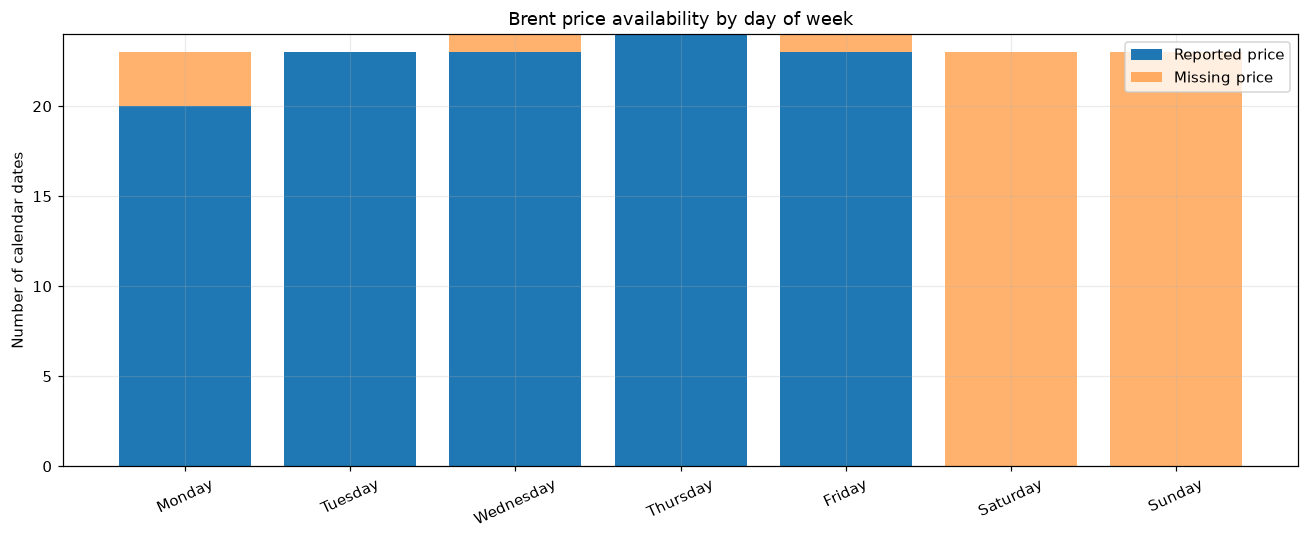

In [3]:
coverage = df[["date", "brent_price"]].copy()
coverage["weekday"] = coverage.date.dt.day_name()
coverage["has_price"] = coverage.brent_price.notna()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = coverage.groupby("weekday")["has_price"].agg(["sum", "count"]).reindex(weekday_order)
weekday["missing"] = weekday["count"] - weekday["sum"]
weekday["pct_observed"] = 100 * weekday["sum"] / weekday["count"]
display(weekday.rename(columns={"sum":"observed", "count":"total_dates"}))
print("Missing prices on weekdays:")
display(coverage.loc[(~coverage.has_price) & (coverage.date.dt.dayofweek < 5), ["date", "weekday"]])
fig, ax = plt.subplots()
xx = np.arange(len(weekday))
ax.bar(xx, weekday["sum"], label="Reported price")
ax.bar(xx, weekday["missing"], bottom=weekday["sum"], label="Missing price", alpha=.6)
ax.set_xticks(xx, weekday_order, rotation=25)
ax.set_ylabel("Number of calendar dates"); ax.set_title("Brent price availability by day of week")
ax.legend()
finish_figure("01_brent_availability_weekdays")

## 4. Brent price level over time
Plot observed prices only. Blank intervals are days without a recorded price; do **not** interpret a connecting line as evidence of weekend prices. Summary statistics refer to reported price observations.

,Brent price (USD/barrel)
count,113.000000
mean,71.884956
std,5.616713
min,60.310000
25%,66.930000
50%,72.360000
75%,76.460000
max,83.480000


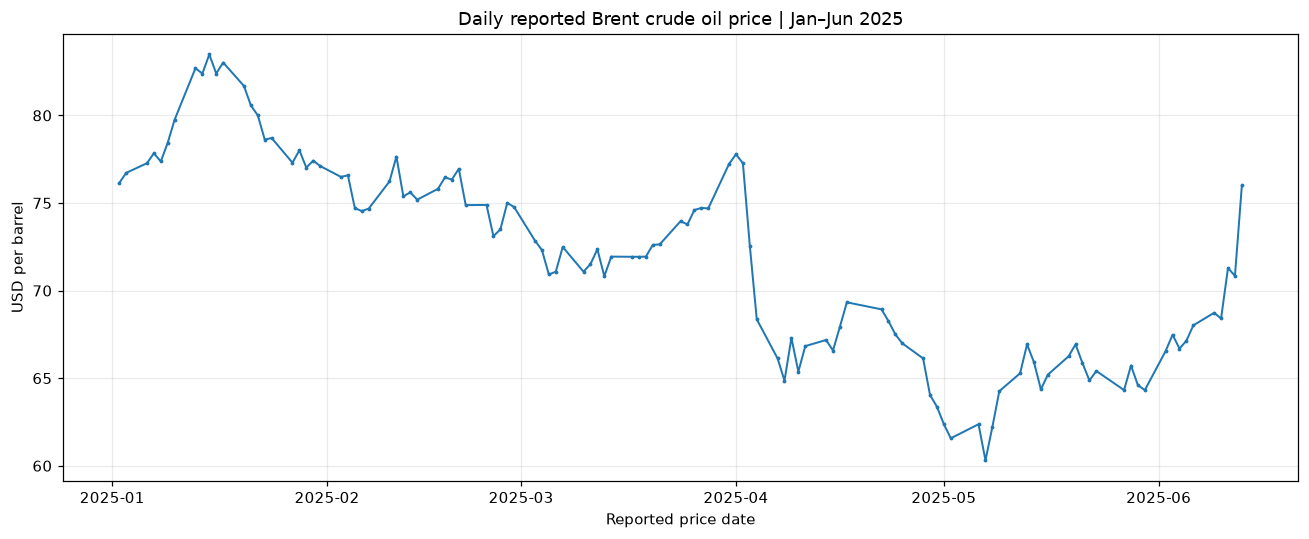

In [4]:
brent_obs = df.loc[df.brent_price.notna(), ["date", "brent_price", "brent_return"]].copy()
display(brent_obs.brent_price.describe().to_frame("Brent price (USD/barrel)"))
fig, ax = plt.subplots()
ax.plot(brent_obs.date, brent_obs.brent_price, marker=".", ms=3, linewidth=1.3)
ax.set_title("Daily reported Brent crude oil price | Jan–Jun 2025")
ax.set_ylabel("USD per barrel"); ax.set_xlabel("Reported price date")
finish_figure("02_brent_price_history")

## 5. Brent returns, volatility, and extremes
`brent_return` is the percentage change between consecutive **observed** Brent prices, so observations after weekends/holidays can span several calendar days. We use percent units in charts, show the distribution, and identify the largest moves. A large price movement does **not** establish the cause.

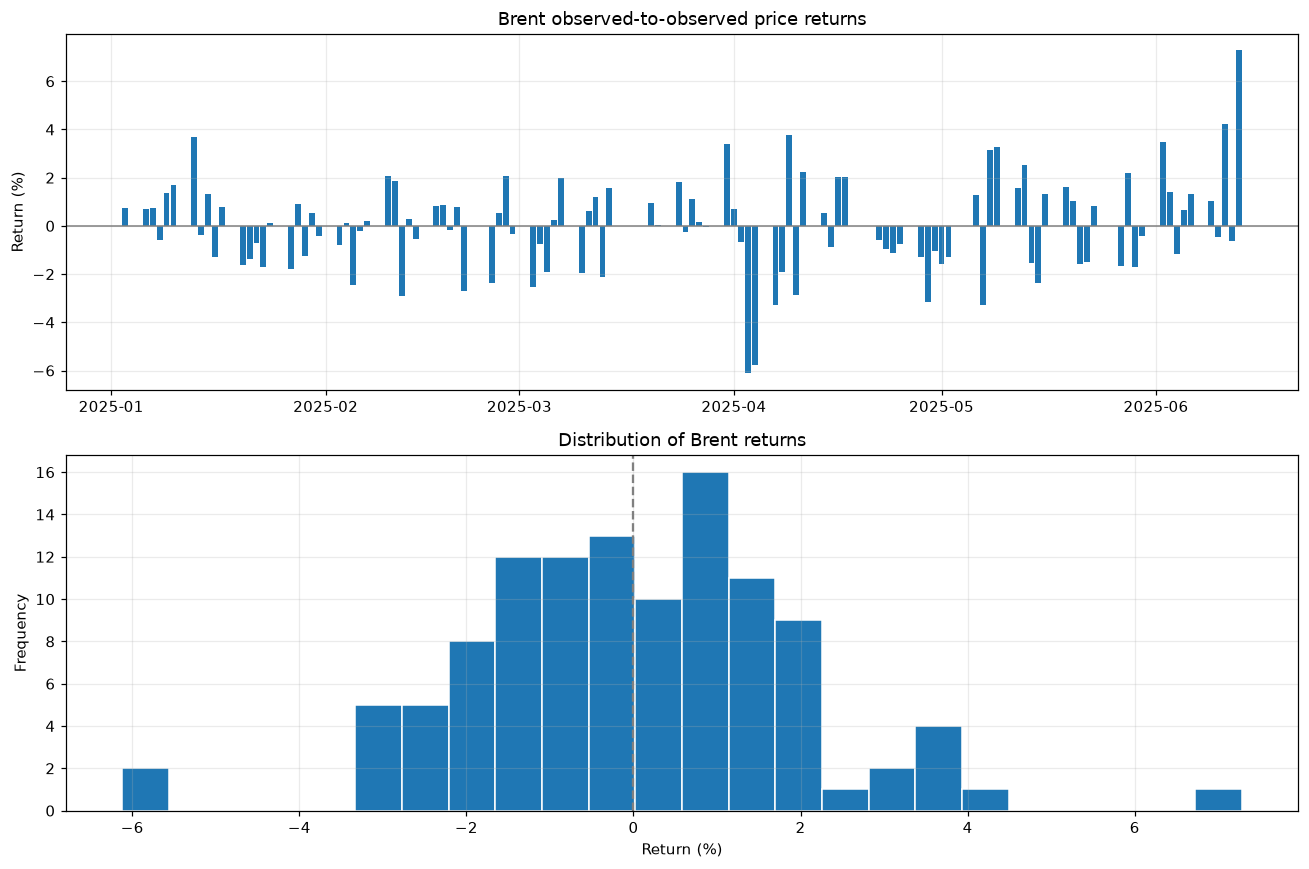

Return statistics (%):


,Return (%)
count,112.000000
mean,0.017547
std,1.968626
min,-6.121393
25%,-1.282944
50%,0.013629
75%,1.216317
max,7.284020


Ten largest absolute recorded-date returns:


,date,brent_price,return_pct
163,2025-06-13,76.00,7.284020
92,2025-04-03,72.54,-6.121393
93,2025-04-04,68.36,-5.762338
161,2025-06-11,71.29,4.209911
98,2025-04-09,67.30,3.761949
12,2025-01-13,82.69,3.673521
152,2025-06-02,66.55,3.467040
89,2025-03-31,77.23,3.400723
126,2025-05-07,60.31,-3.302870
128,2025-05-09,64.26,3.278689


In [5]:
returns = brent_obs.dropna(subset=["brent_return"]).copy()
returns["return_pct"] = 100 * returns.brent_return
fig, axs = plt.subplots(2, 1, figsize=(12, 8))
axs[0].axhline(0, linewidth=1, color="gray")
axs[0].bar(returns.date, returns.return_pct, width=.85)
axs[0].set_title("Brent observed-to-observed price returns"); axs[0].set_ylabel("Return (%)")
axs[1].hist(returns.return_pct, bins=24, edgecolor="white")
axs[1].axvline(0, color="gray", linestyle="--")
axs[1].set_title("Distribution of Brent returns"); axs[1].set_xlabel("Return (%)"); axs[1].set_ylabel("Frequency")
finish_figure("03_brent_returns_and_distribution")
print("Return statistics (%):")
display(returns.return_pct.describe().to_frame("Return (%)"))
print("Ten largest absolute recorded-date returns:")
display(returns.assign(abs_return=returns.return_pct.abs()).nlargest(10, "abs_return")[["date", "brent_price", "return_pct"]])

## 6. Worldwide event volume and oil-country activity
Compare total GDELT event count with exporter and importer activity. The exporter and importer categories can overlap, so their counts should **not** be added together as distinct events. Use the oil-country *union share* for unique coverage.

Daily geopolitical activity summary:


,count,mean,std,min,25%,50%,75%,max
global_total_events,164.0,124043.707317,28783.322643,64742.00000,91469.500000,136635.000000,147858.000000,161604.000000
exporter_total_events,164.0,10440.182927,2692.792731,5758.00000,8720.250000,10588.000000,12124.000000,22040.000000
importer_total_events,164.0,46655.286585,11888.179508,21070.00000,35284.750000,51694.000000,56141.500000,63607.000000
oil_country_event_share,164.0,0.446495,0.016333,0.39602,0.438429,0.446202,0.456344,0.501638


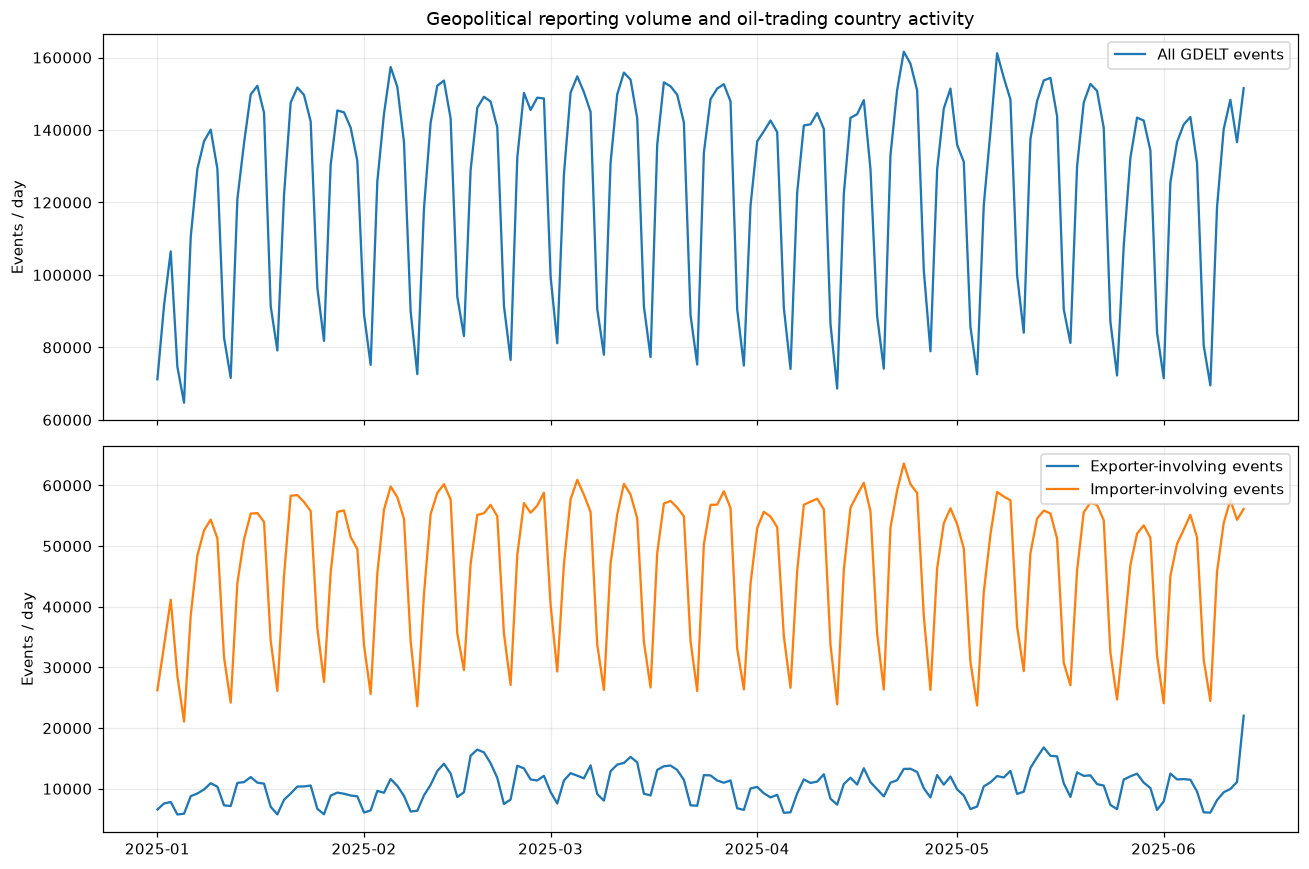

Highest total event-volume dates:


,date,global_total_events,oil_country_event_share
112,2025-04-23,161604.0,0.461696
126,2025-05-07,161183.0,0.428333
113,2025-04-24,158308.0,0.450628
35,2025-02-05,157391.0,0.444053
70,2025-03-12,155839.0,0.461155
63,2025-03-05,154805.0,0.459778
127,2025-05-08,154460.0,0.438269
134,2025-05-15,154382.0,0.445823


In [6]:
print("Daily geopolitical activity summary:")
display(df[["global_total_events", "exporter_total_events", "importer_total_events", "oil_country_event_share"]].describe().T)
fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axs[0].plot(df.date, df.global_total_events, label="All GDELT events")
axs[0].set_ylabel("Events / day"); axs[0].legend()
axs[1].plot(df.date, df.exporter_total_events, label="Exporter-involving events")
axs[1].plot(df.date, df.importer_total_events, label="Importer-involving events")
axs[1].set_ylabel("Events / day"); axs[1].legend()
axs[0].set_title("Geopolitical reporting volume and oil-trading country activity")
finish_figure("04_geopolitical_event_activity")
print("Highest total event-volume dates:")
display(df.nlargest(8, "global_total_events")[["date", "global_total_events", "oil_country_event_share"]])

## 7. CAMEO geopolitical event composition
Plot total root-category counts and relative shares. The global feature set contains **20 CAMEO root codes**. `EventRootCode` expresses event **types**, not necessarily verified real-world incident counts. Event reporting frequency can vary with news coverage.

Events represented in 20 roots: 20,343,152
Total GDELT events: 20,343,168


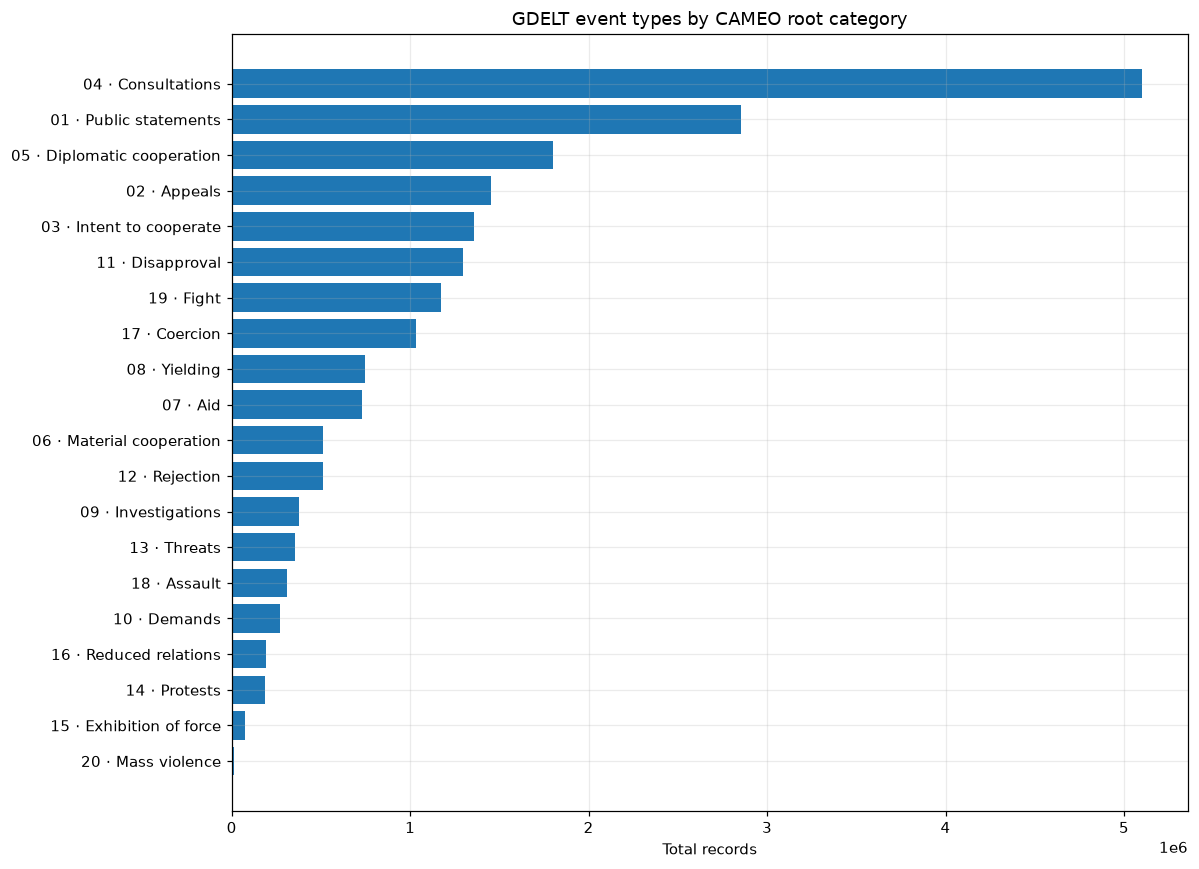

,event_count,share_of_all_events
global_root_04,5103696.0,0.250880
global_root_01,2856569.0,0.140419
global_root_05,1799597.0,0.088462
global_root_02,1450320.0,0.071293
global_root_03,1359217.0,0.066814
global_root_11,1294549.0,0.063636
global_root_19,1171487.0,0.057586
global_root_17,1031142.0,0.050687
global_root_08,746460.0,0.036693
global_root_07,729467.0,0.035858


In [7]:
CAMEO_ROOT_LABELS = {
    "01":"Public statements", "02":"Appeals", "03":"Intent to cooperate", "04":"Consultations", "05":"Diplomatic cooperation",
    "06":"Material cooperation", "07":"Aid", "08":"Yielding", "09":"Investigations", "10":"Demands",
    "11":"Disapproval", "12":"Rejection", "13":"Threats", "14":"Protests", "15":"Exhibition of force",
    "16":"Reduced relations", "17":"Coercion", "18":"Assault", "19":"Fight", "20":"Mass violence"
}
root_cols = [f"global_root_{i:02d}" for i in range(1, 21) if f"global_root_{i:02d}" in df]
root_totals = df[root_cols].sum().sort_values(ascending=False)
labels = [f"{c[-2:]} · {CAMEO_ROOT_LABELS.get(c[-2:], 'Other')}" for c in root_totals.index]
print("Events represented in 20 roots:", f"{root_totals.sum():,.0f}")
print("Total GDELT events:", f"{df.global_total_events.sum():,.0f}")
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(labels[::-1], root_totals.values[::-1])
ax.set_title("GDELT event types by CAMEO root category")
ax.set_xlabel("Total records")
finish_figure("05_cameo_root_counts")
display(pd.DataFrame({"event_count": root_totals, "share_of_all_events": root_totals / df.global_total_events.sum()}).head(12))

## 8. Goldstein scores, weighted impact, and news tone
Compare exporter/importer/global Goldstein means and news tone over time. The **Goldstein Impact Index is not bounded by −10 to +10**: it is `sum(GoldsteinScale_Adjusted × NumMentions) / number_of_valid_events` (as implemented following the project's reading of Vodenska et al.). The notebook deliberately **does not clip** these values.

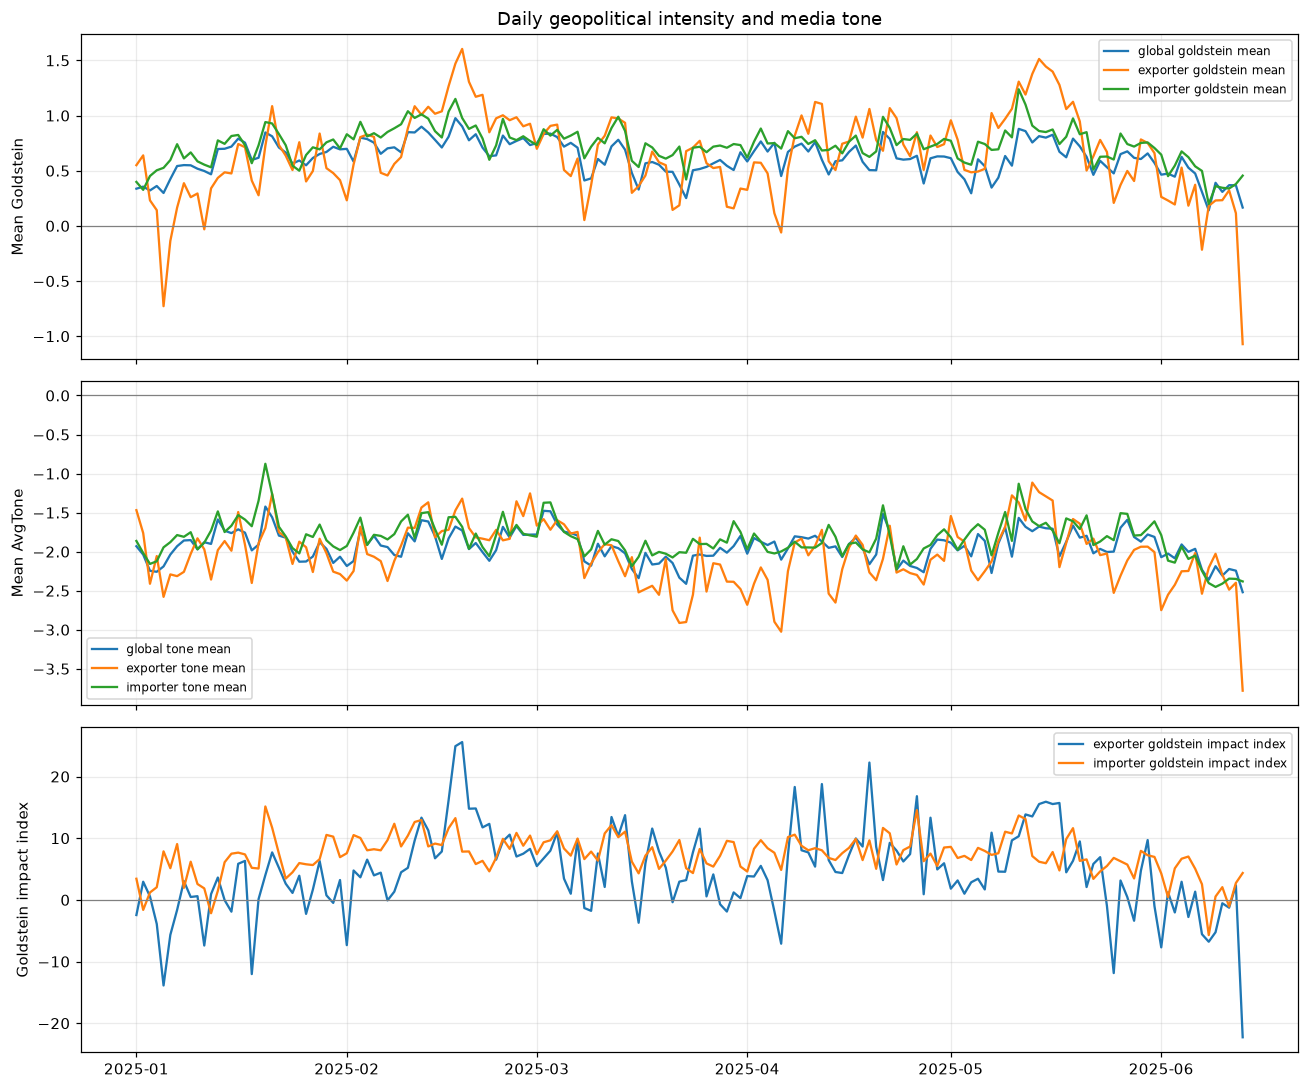

exporter_goldstein_impact_index: min=-22.28, median=4.44, max=25.59
importer_goldstein_impact_index: min=-5.71, median=7.45, max=15.14


In [8]:
fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for col in ["global_goldstein_mean", "exporter_goldstein_mean", "importer_goldstein_mean"]:
    axs[0].plot(df.date, df[col], label=col.replace("_", " "))
axs[0].axhline(0, color="gray", lw=.8); axs[0].set_ylabel("Mean Goldstein"); axs[0].legend(fontsize=8)
for col in ["global_tone_mean", "exporter_tone_mean", "importer_tone_mean"]:
    axs[1].plot(df.date, df[col], label=col.replace("_", " "))
axs[1].axhline(0, color="gray", lw=.8); axs[1].set_ylabel("Mean AvgTone"); axs[1].legend(fontsize=8)
for col in ["exporter_goldstein_impact_index", "importer_goldstein_impact_index"]:
    axs[2].plot(df.date, df[col], label=col.replace("_", " "))
axs[2].axhline(0, color="gray", lw=.8); axs[2].set_ylabel("Goldstein impact index"); axs[2].legend(fontsize=8)
axs[0].set_title("Daily geopolitical intensity and media tone")
finish_figure("06_goldstein_tone_impact")
for col in ["exporter_goldstein_impact_index", "importer_goldstein_impact_index"]:
    print(f"{col}: min={df[col].min():.2f}, median={df[col].median():.2f}, max={df[col].max():.2f}")

## 9. News attention, reporting bias proxies, and country involvement
Examine mentions, articles, the rate of negative tone, and actor-country missingness. `NumArticles` sums are **event-associated**, not counts of unique articles; a single article may relate to multiple events.

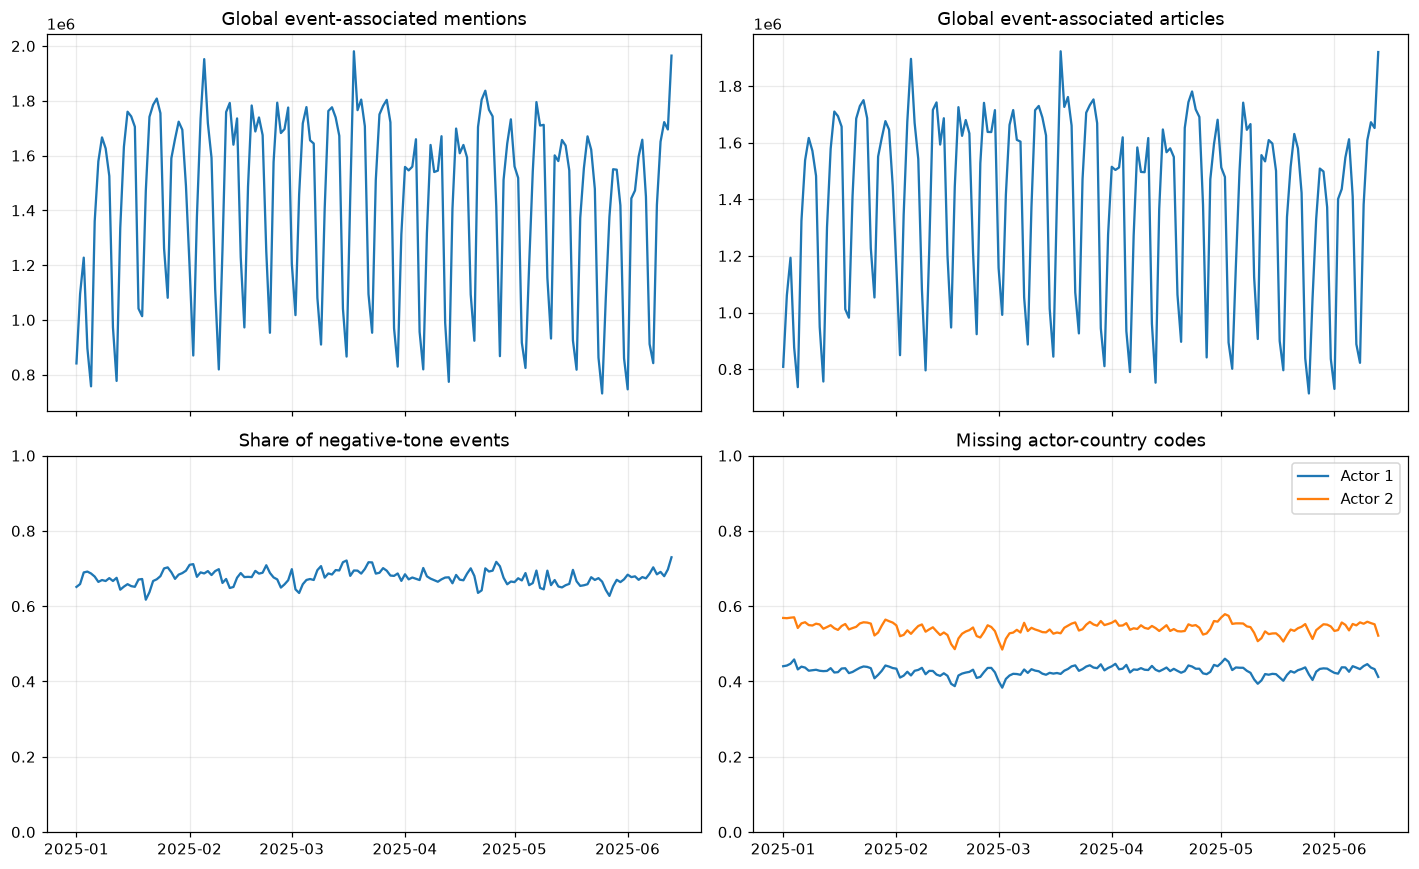

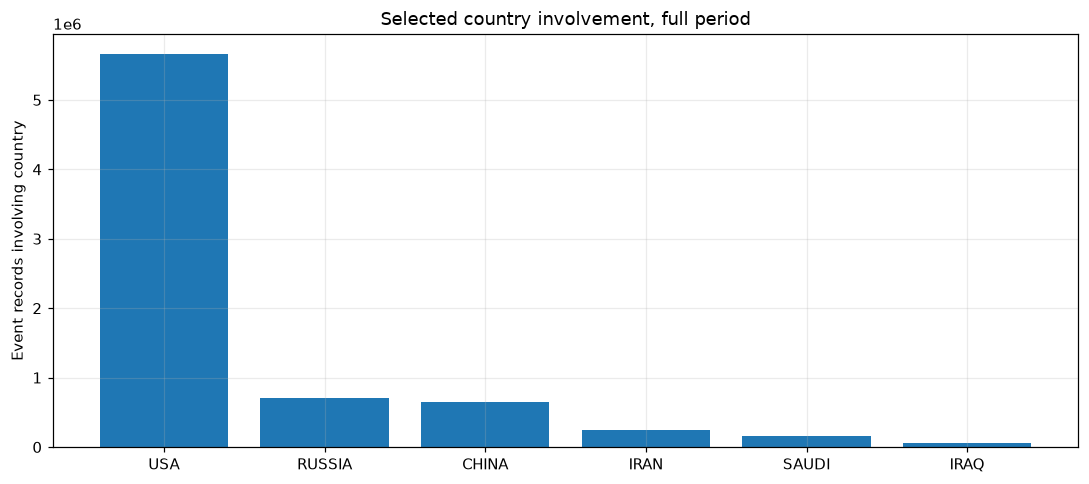

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
axs[0,0].plot(df.date, df.global_total_mentions)
axs[0,0].set_title("Global event-associated mentions")
axs[0,1].plot(df.date, df.global_total_articles)
axs[0,1].set_title("Global event-associated articles")
axs[1,0].plot(df.date, df.global_negative_tone_share)
axs[1,0].set_title("Share of negative-tone events"); axs[1,0].set_ylim(0,1)
axs[1,1].plot(df.date, df.actor1_country_missing_share, label="Actor 1")
axs[1,1].plot(df.date, df.actor2_country_missing_share, label="Actor 2")
axs[1,1].set_title("Missing actor-country codes"); axs[1,1].set_ylim(0,1); axs[1,1].legend()
finish_figure("07_media_attention_and_data_quality")
country_cols = [c for c in ["iran_total_events", "saudi_total_events", "russia_total_events", "iraq_total_events", "usa_total_events", "china_total_events"] if c in df]
country_summary = df[country_cols].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar([c.replace("_total_events", "").upper() for c in country_summary.index], country_summary.values)
ax.set_ylabel("Event records involving country"); ax.set_title("Selected country involvement, full period")
finish_figure("08_major_country_counts")

## 10. Feature distributions, skewness, and possible transformations
Inspect representative count and signed variables. We use `log1p` only for nonnegative counts, `arcsinh` for signed high-magnitude impact values, and leave bounded shares and mean scores unchanged. These are **visual diagnostics only**—the saved source features are not altered.

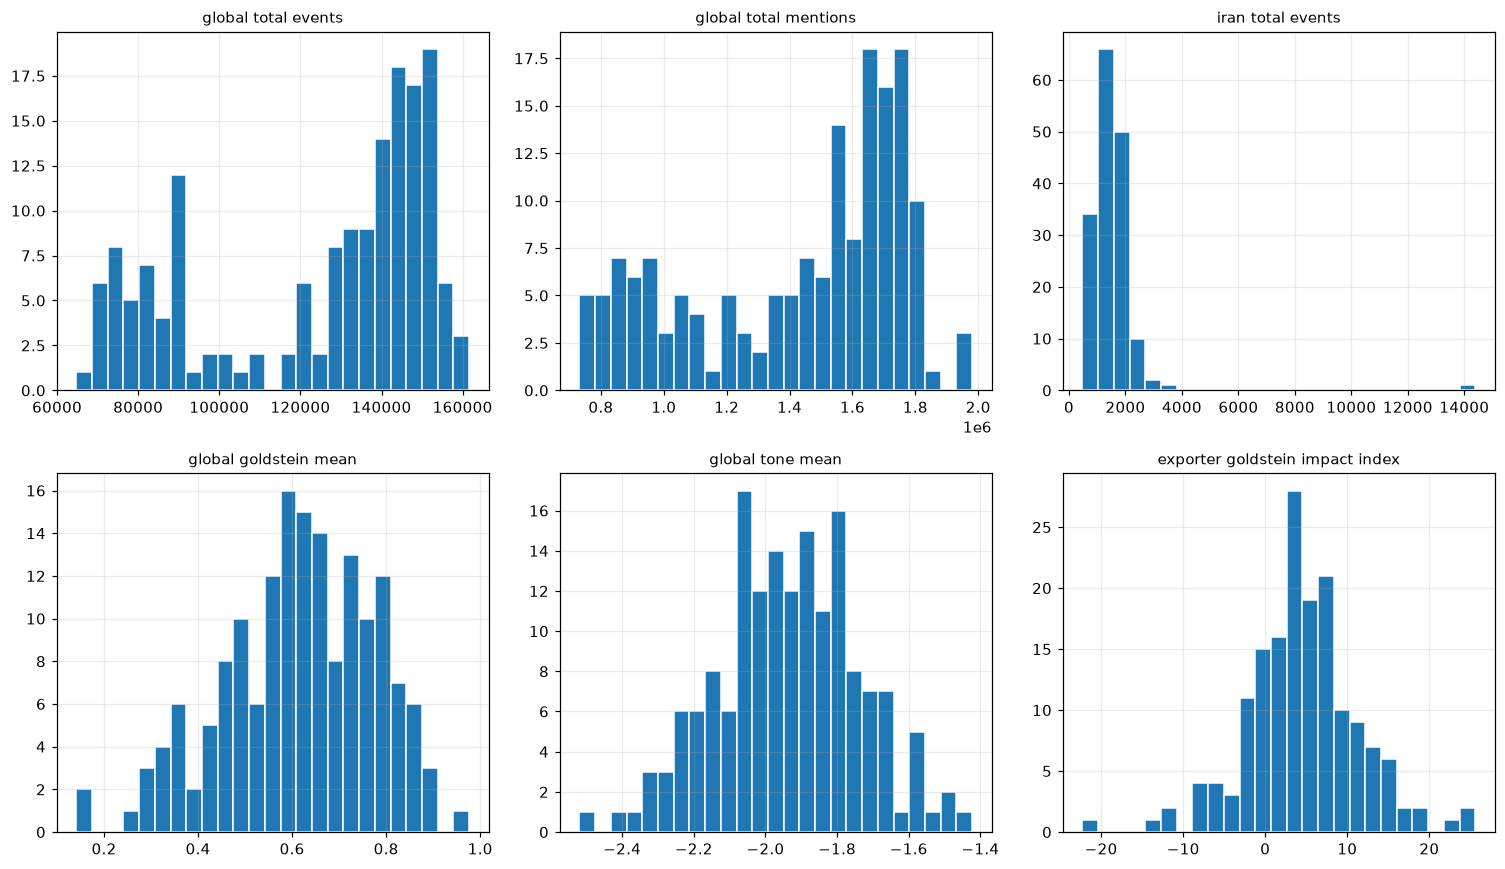

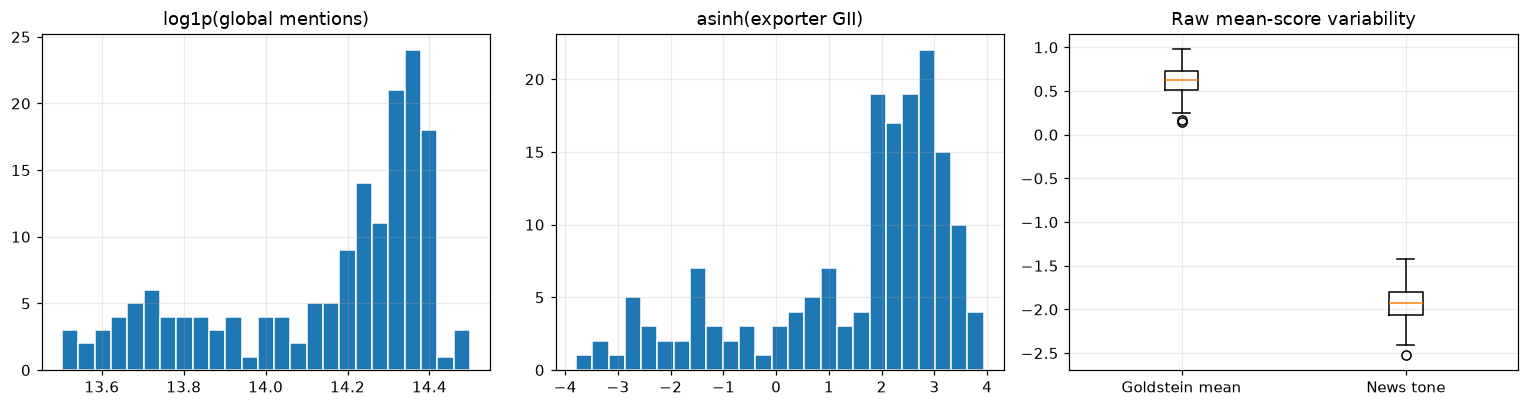

Highest absolute exporter impact index days:


,date,exporter_goldstein_impact_index,exporter_total_events,exporter_total_mentions
48,2025-02-18,25.587601,16453.0,183479.0
47,2025-02-17,24.921270,15454.0,176608.0
163,2025-06-13,-22.278162,22040.0,319924.0
108,2025-04-19,22.265139,9905.0,125463.0
101,2025-04-12,18.779890,8354.0,119746.0
97,2025-04-08,18.305930,11534.0,132599.0
115,2025-04-26,16.812898,10087.0,176797.0
46,2025-02-16,16.168241,9424.0,89383.0


In [10]:
distribution_features = ["global_total_events", "global_total_mentions", "iran_total_events", "global_goldstein_mean", "global_tone_mean", "exporter_goldstein_impact_index"]
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axs.flat, distribution_features):
    vals = df[col].dropna().astype(float)
    ax.hist(vals, bins=25, edgecolor="white")
    ax.set_title(col.replace("_", " "), fontsize=10)
finish_figure("09_feature_distributions")
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].hist(np.log1p(df.global_total_mentions), bins=25, edgecolor="white")
axs[0].set_title("log1p(global mentions)")
axs[1].hist(np.arcsinh(df.exporter_goldstein_impact_index), bins=25, edgecolor="white")
axs[1].set_title("asinh(exporter GII)")
axs[2].boxplot([df.global_goldstein_mean.dropna(), df.global_tone_mean.dropna()], tick_labels=["Goldstein mean", "News tone"])
axs[2].set_title("Raw mean-score variability")
finish_figure("10_transform_diagnostics")
print("Highest absolute exporter impact index days:")
display(df.assign(abs_gii=df.exporter_goldstein_impact_index.abs()).nlargest(8, "abs_gii")[["date", "exporter_goldstein_impact_index", "exporter_total_events", "exporter_total_mentions"]])

## 11. Same-day associations: descriptive **only**
Correlations using GDELT data and Brent returns on the **same reported date** can involve information that arrived *after* the relevant pricing window. These results are provided solely as descriptive benchmarks, **not predictive evidence**. Correlation does not establish causation; multiple comparisons and short samples create a substantial chance of accidental patterns.

Same-date Pearson correlation with Brent return (descriptive, noncausal):


,Pearson r
exporter_root_19,0.435377
iran_total_events,0.376034
oil_country_event_share,0.299708
exporter_goldstein_impact_index,-0.252018
global_goldstein_mean,-0.221300
exporter_goldstein_mean,-0.218337
importer_goldstein_mean,-0.186355
global_root_20,-0.144058
global_tone_mean,-0.139978
global_total_events,-0.132206


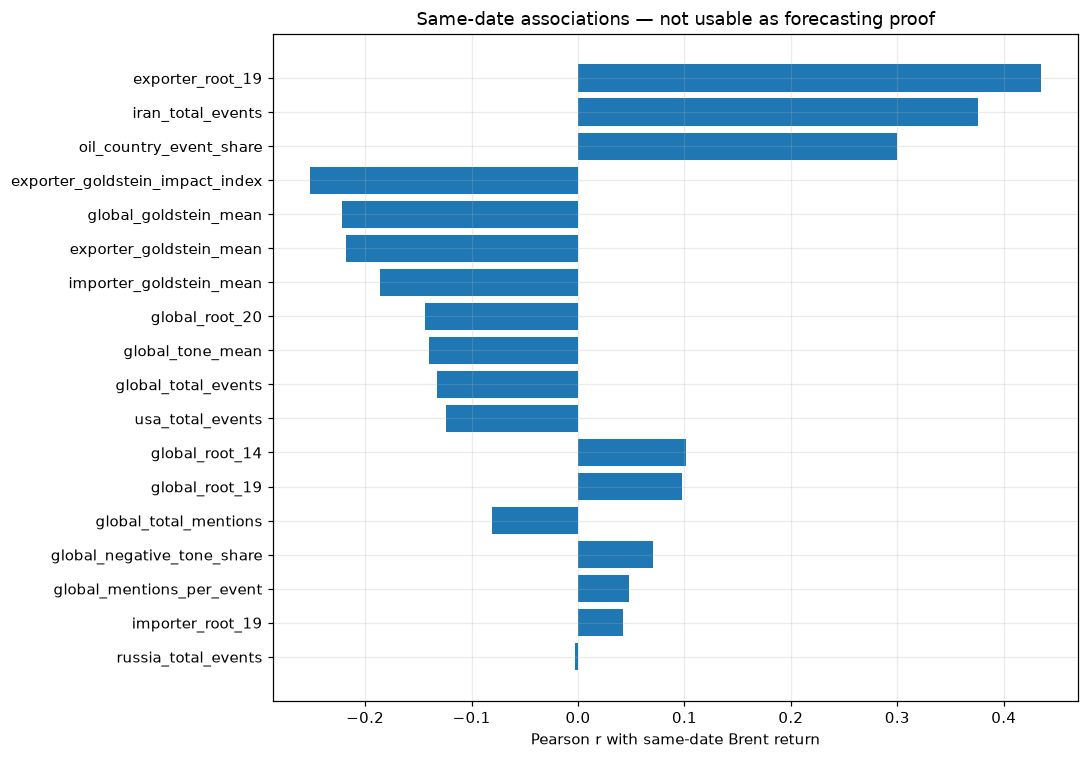

In [11]:
selected = ["global_total_events", "oil_country_event_share", "global_root_14", "global_root_19", "global_root_20", "exporter_root_19", "importer_root_19", "global_goldstein_mean", "exporter_goldstein_mean", "importer_goldstein_mean", "exporter_goldstein_impact_index", "global_tone_mean", "global_negative_tone_share", "global_total_mentions", "global_mentions_per_event", "iran_total_events", "russia_total_events", "usa_total_events"]
selected = [c for c in selected if c in df]
trading = df.loc[df.brent_return.notna()].copy()
cor_same = trading[selected + ["brent_return"]].corr(method="pearson")["brent_return"].drop("brent_return").sort_values(key=lambda x:x.abs(), ascending=False)
print("Same-date Pearson correlation with Brent return (descriptive, noncausal):")
display(cor_same.to_frame("Pearson r"))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(cor_same.index[::-1], cor_same.values[::-1])
ax.set_xlabel("Pearson r with same-date Brent return")
ax.set_title("Same-date associations — not usable as forecasting proof")
finish_figure("11_same_day_correlations")

## 12. Scatterplots: illustrative geopolitical associations
Inspect whether associations appear linear, driven by outliers, or absent. Points are reported-price days. These are **same-date plots**, so their slopes cannot be interpreted as predictive or causal effects.

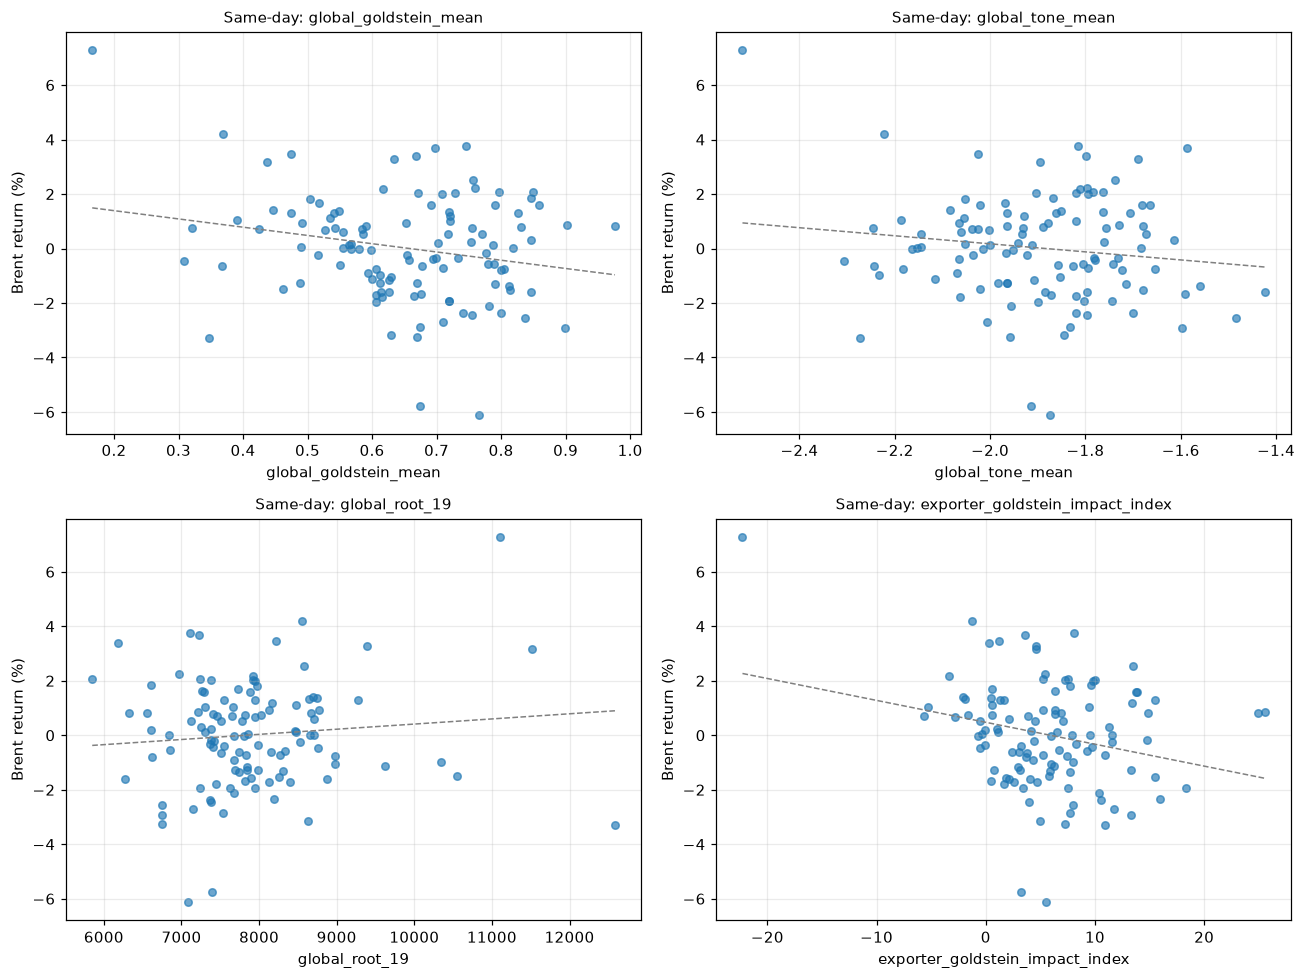

In [12]:
scatter_features = ["global_goldstein_mean", "global_tone_mean", "global_root_19", "exporter_goldstein_impact_index"]
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
for ax, feature in zip(axs.flat, scatter_features):
    x = trading[feature].to_numpy(float)
    y = 100 * trading.brent_return.to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    ax.scatter(x[valid], y[valid], alpha=.65, s=24)
    if valid.sum() > 2 and np.std(x[valid]) > 0:
        coefficients = np.polyfit(x[valid], y[valid], 1)
        grid = np.linspace(x[valid].min(), x[valid].max(), 100)
        ax.plot(grid, np.polyval(coefficients, grid), linestyle="--", lw=1, color="gray")
    ax.set_xlabel(feature); ax.set_ylabel("Brent return (%)")
    ax.set_title(f"Same-day: {feature}", fontsize=10)
finish_figure("12_scatter_same_day")

## 13. Lagged correlations using **prior calendar days**
For a Brent price observation dated **t**, test geopolitical features dated **t−1**, **t−2**, and **t−3 calendar days**. This is stricter than same-date alignment and prevents directly using day-*t* GDELT event totals. It does **not** guarantee operational availability without timestamp-level auditing, and the correlations remain exploratory. Calendar-day lags are **not** trading-day lags.

The paper's two-day media-signal finding used GDELT **GKG**, whereas this project uses GDELT **Events**: treat 2 days as a candidate hypothesis, not a confirmed optimal lag.

Lagged correlations (exploratory, NOT a forecasting performance test):


,feature,prior_calendar_days,n_pairs,pearson_r
9,global_goldstein_mean,1,112,-0.267027
11,global_goldstein_mean,3,111,-0.257904
10,global_goldstein_mean,2,112,-0.207875
15,global_tone_mean,1,112,-0.181993
21,iran_total_events,1,112,0.181057
14,exporter_goldstein_impact_index,3,111,-0.161842
8,global_root_19,3,111,0.159022
16,global_tone_mean,2,112,-0.158342
17,global_tone_mean,3,111,-0.156351
5,global_root_14,3,111,0.097697


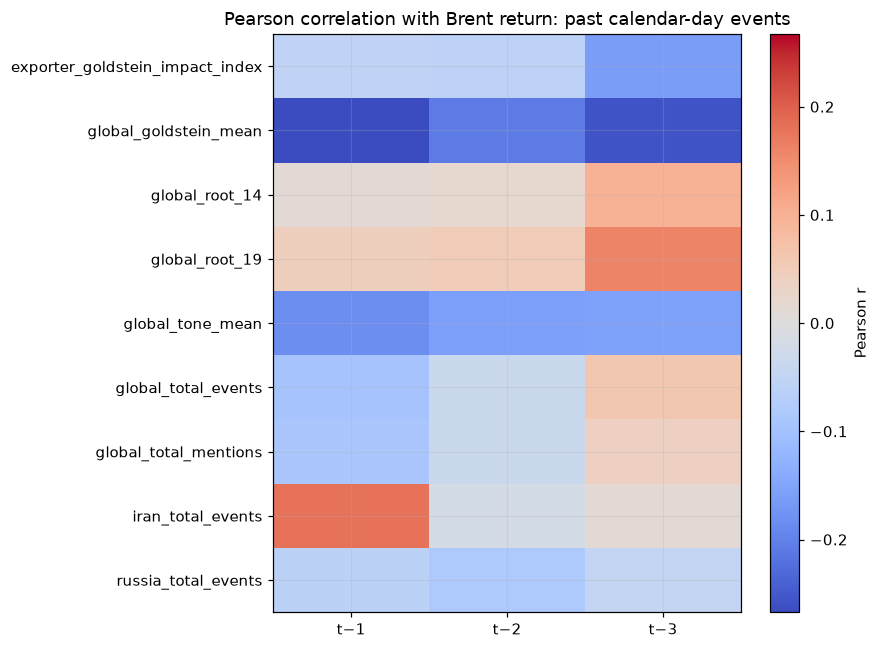

In [13]:
lag_features = ["global_total_events", "global_root_14", "global_root_19", "global_goldstein_mean", "exporter_goldstein_impact_index", "global_tone_mean", "global_total_mentions", "iran_total_events", "russia_total_events"]
lag_features = [c for c in lag_features if c in df]
lagged = df[["date", "brent_return"]].copy()
for lag in [1,2,3]:
    for feature in lag_features:
        lagged[f"{feature}_lag{lag}d"] = df[feature].shift(lag)
lagged = lagged.loc[lagged.brent_return.notna()]
lag_records = []
for feature in lag_features:
    for lag in [1,2,3]:
        col = f"{feature}_lag{lag}d"
        pair = lagged[[col, "brent_return"]].dropna()
        r = pair[col].corr(pair.brent_return) if len(pair) >= 10 and pair[col].nunique() > 1 else np.nan
        lag_records.append({"feature": feature, "prior_calendar_days": lag, "n_pairs":len(pair), "pearson_r":r})
lag_summary = pd.DataFrame(lag_records)
print("Lagged correlations (exploratory, NOT a forecasting performance test):")
display(lag_summary.sort_values("pearson_r", key=lambda s:s.abs(), ascending=False).head(20))
pivot = lag_summary.pivot(index="feature", columns="prior_calendar_days", values="pearson_r")
fig, ax = plt.subplots(figsize=(8, 6))
values = pivot.to_numpy()
im = ax.imshow(values, cmap="coolwarm", vmin=-max(.15, np.nanmax(np.abs(values))), vmax=max(.15, np.nanmax(np.abs(values))), aspect="auto")
ax.set_yticks(np.arange(len(pivot)), pivot.index)
ax.set_xticks([0,1,2], ["t−1", "t−2", "t−3"])
ax.set_title("Pearson correlation with Brent return: past calendar-day events")
plt.colorbar(im, ax=ax, label="Pearson r")
finish_figure("13_prior_calendar_day_lag_heatmap")

## 14. Weekend and holiday news between consecutive Brent observations
A price observation after several non-reporting days may reflect accumulated prior geopolitical news. For each observed Brent price date, aggregate GDELT **between the previous price-observation date (inclusive) and the current observation date (exclusive)**. This counts every calendar-day event once in the preceding price-to-price interval, *including the prior observation date* because intraday price/data cutoffs are unknown. This is an exploratory **as-of previous calendar day** proxy, **not** a time-stamped investable strategy. The earliest observation has no preceding observed-price date inside this dataset and is excluded.

We compute summed event and media volume, an event-weighted mean Goldstein score, and number of preceding calendar days. The latter varies on weekends/holidays and is a potential confounder.

Price intervals available: 112
Interval day-count distribution:


,intervals
days_in_window,
1,89
3,20
4,2
5,1


,Pearson r vs subsequent observed return
event_weighted_goldstein_before_price_date,-0.300594
events_per_calendar_day,-0.096421
conflict19_before_price_date,0.070469
days_in_window,0.053795
protest14_before_price_date,0.046506
events_before_price_date,0.026608
mentions_before_price_date,0.021256


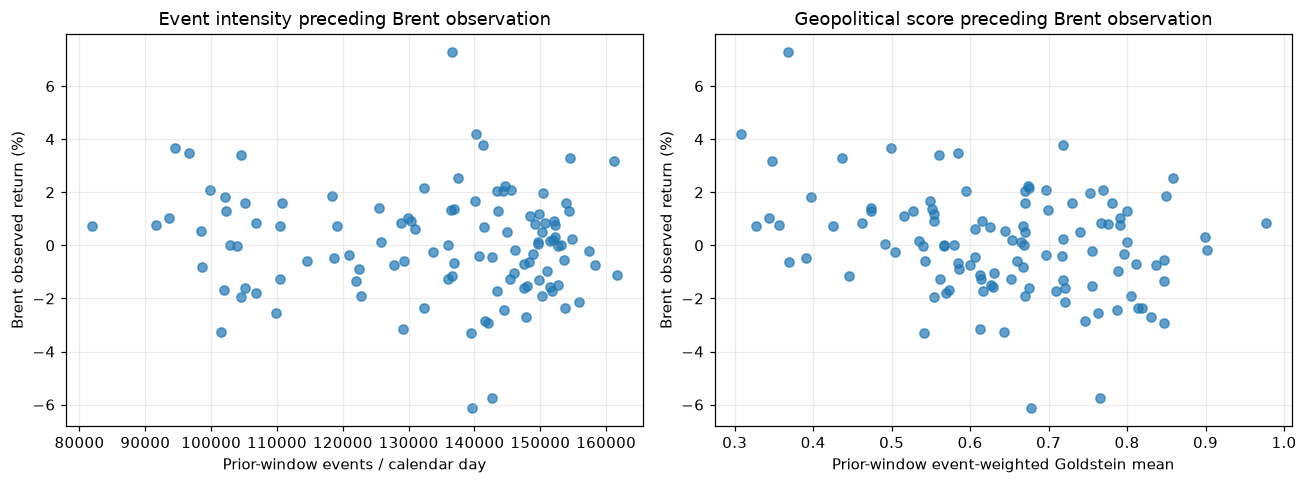

In [14]:
price_days = df.loc[df.brent_price.notna(), ["date", "brent_price", "brent_return"]].copy().reset_index(drop=True)
price_days["previous_price_date"] = price_days.date.shift(1)
window_rows = []
for item in price_days.itertuples(index=False):
    if pd.isna(item.previous_price_date):
        continue
    window = df.loc[(df.date >= item.previous_price_date) & (df.date < item.date)]
    if window.empty:
        continue
    count = window.global_total_events.sum()
    window_rows.append({
        "date":item.date, "previous_price_date":item.previous_price_date,
        "days_in_window":len(window), "brent_return":item.brent_return,
        "events_before_price_date":count,
        "mentions_before_price_date":window.global_total_mentions.sum(),
        "conflict19_before_price_date":window.global_root_19.sum(),
        "protest14_before_price_date":window.global_root_14.sum(),
        "event_weighted_goldstein_before_price_date": (window.global_goldstein_mean * window.global_total_events).sum()/count if count else np.nan,
    })
window_df = pd.DataFrame(window_rows)
window_df["events_per_calendar_day"] = window_df.events_before_price_date / window_df.days_in_window
print("Price intervals available:",len(window_df))
print("Interval day-count distribution:")
display(window_df.days_in_window.value_counts().sort_index().to_frame("intervals"))
window_features = ["events_before_price_date", "events_per_calendar_day", "mentions_before_price_date", "conflict19_before_price_date", "protest14_before_price_date", "event_weighted_goldstein_before_price_date", "days_in_window"]
window_cor = window_df[window_features + ["brent_return"]].corr()["brent_return"].drop("brent_return").sort_values(key=lambda s:s.abs(), ascending=False)
display(window_cor.to_frame("Pearson r vs subsequent observed return"))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].scatter(window_df.events_per_calendar_day, 100 * window_df.brent_return, alpha=.7)
axs[0].set_xlabel("Prior-window events / calendar day"); axs[0].set_ylabel("Brent observed return (%)")
axs[0].set_title("Event intensity preceding Brent observation")
axs[1].scatter(window_df.event_weighted_goldstein_before_price_date, 100*window_df.brent_return, alpha=.7)
axs[1].set_xlabel("Prior-window event-weighted Goldstein mean")
axs[1].set_ylabel("Brent observed return (%)")
axs[1].set_title("Geopolitical score preceding Brent observation")
finish_figure("14_inter_observation_window_scatter")

## 15. Outliers, robust associations, and sample-size limitations
Check whether the lagged patterns are driven by a few observations by comparing Pearson with rank-based Spearman correlations. Report **n** for each estimate. This remains hypothesis screening: inspecting many features/lags without held-out evaluation can lead to data dredging.

In [15]:
robust_rows = []
for feature in lag_features:
    for lag in [1,2,3]:
        col = f"{feature}_lag{lag}d"
        subset = lagged[[col, "brent_return"]].dropna()
        if len(subset) < 10 or subset[col].nunique() < 2:
            continue
        robust_rows.append({"feature":feature, "lag_days":lag, "n":len(subset),
                            "pearson_r": subset[col].corr(subset.brent_return, method="pearson"),
                            "spearman_r":subset[col].corr(subset.brent_return, method="spearman")})
robust_df = pd.DataFrame(robust_rows)
robust_df["abs_correlation_disagreement"] = (robust_df.pearson_r - robust_df.spearman_r).abs()
print("Largest Pearson/Spearman disagreements:")
display(robust_df.nlargest(12, "abs_correlation_disagreement"))
print("Sample length is approximately six months; seasonality, structural stability, and claims of predictive utility CANNOT be robustly established from these correlations alone.")

Largest Pearson/Spearman disagreements:


,feature,lag_days,n,pearson_r,spearman_r,abs_correlation_disagreement
21,iran_total_events,1,112,0.181057,0.008568,0.172489
4,global_root_14,2,112,0.019241,-0.095574,0.114815
3,global_root_14,1,112,0.012214,-0.098486,0.110701
15,global_tone_mean,1,112,-0.181993,-0.119631,0.062362
9,global_goldstein_mean,1,112,-0.267027,-0.208597,0.058431
7,global_root_19,2,112,0.048671,-0.007696,0.056368
17,global_tone_mean,3,111,-0.156351,-0.106722,0.049630
23,iran_total_events,3,111,0.012327,-0.022951,0.035278
6,global_root_19,1,112,0.042125,0.009332,0.032793
5,global_root_14,3,111,0.097697,0.067806,0.029892


Sample length is approximately six months; seasonality, structural stability, and claims of predictive utility CANNOT be robustly established from these correlations alone.


## 16. Summary and export for report drafting
Produce machine-readable findings for later interpretation. These tables are **not** statements of significance or causality. Save them in `outputs/eda_brent/`; the original GDELT–Brent data remains unchanged. Do not upload only the static code: **run all cells and upload the executed `.ipynb` so the printed tables and plots are included**.

In [16]:
summary = pd.DataFrame([{
    "start_date": df.date.min().date().isoformat(),
    "end_date": df.date.max().date().isoformat(),
    "calendar_days": len(df),
    "feature_columns_including_date_and_prices": df.shape[1],
    "reported_brent_prices": int(df.brent_price.notna().sum()),
    "missing_brent_prices": int(df.brent_price.isna().sum()),
    "valid_brent_returns": int(df.brent_return.notna().sum()),
    "total_gdelt_events": int(df.global_total_events.sum()),
    "price_interval_rows": len(window_df),
}])
display(summary)
if EXPORT_FIGURES:
    cor_same.rename("pearson_r").to_csv(OUT_DIR / "same_day_correlations_descriptive.csv", header=True)
    lag_summary.to_csv(OUT_DIR / "lagged_correlations_exploratory.csv", index=False)
    robust_df.to_csv(OUT_DIR / "lagged_pearson_spearman.csv", index=False)
    window_df.to_csv(OUT_DIR / "preceding_price_window_features.csv", index=False)
    summary.to_csv(OUT_DIR / "eda_dataset_summary.csv", index=False)
    print("Saved chart images and analysis tables to:", OUT_DIR)
print("EDA notebook finished. Upload the executed .ipynb for interpretation; do not infer causation from observed correlations.")

,start_date,end_date,calendar_days,feature_columns_including_date_and_prices,reported_brent_prices,missing_brent_prices,valid_brent_returns,total_gdelt_events,price_interval_rows
0,2025-01-01,2025-06-13,164,86,113,51,112,20343168,112


Saved chart images and analysis tables to: c:\Users\kevin\school\Fall 2026\Data Intensive Computing\DIC Semeters Project\Phase 2\Data_wizards\outputs\eda_brent
EDA notebook finished. Upload the executed .ipynb for interpretation; do not infer causation from observed correlations.


---
### Interpretation checklist for the next discussion
- What were the largest Brent returns, and on which observed-price dates did they occur?
- Did geopolitical reporting volume and specific CAMEO categories show spikes? Were those spikes event-specific or overall news volume?
- Which correlations are unstable across Pearson/Spearman or across 1-, 2-, and 3-day lags?
- Do preceding **price-interval** aggregates behave differently from calendar-day lags?
- Are extremes in the Goldstein Impact Index plausible consequences of mention weighting?
- Which features merit subsequent *chronological* model testing after accounting for multiple comparisons and the small number of available trading observations?

**Do not select a final model solely from the highest EDA correlation.**